# Fraud Detection in Online Card Transactions

**Goal:** flag fraudulent card transactions so that analysts review the right alerts, and decide *how many alerts to raise* so that the fraud team saves more money than it spends.

**Dataset:** Credit Card Fraud Detection (ULB / Worldline), about 285K European card transactions over two days, of which roughly 0.17% are fraud. Features `V1`-`V28` are PCA components (anonymized), plus `Time`, `Amount` and the label `Class`. Download it from Kaggle into `data/` (see `data/README.md`).

**Approach**
1. Validate the data and look at the imbalance
2. Explore what separates fraud from legitimate transactions
3. Split **by time** (train, validation, test), because shuffling would leak the future into the past
4. Compare a supervised baseline, an unsupervised anomaly detector and tuned gradient boosting
5. Pick the alert threshold by **net savings** (fraud prevented minus review cost)
6. Evaluate once on the final, most recent slice of time

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = Path("../data/creditcard.csv")
sns.set_theme(style="whitegrid")

## 2. Load and validate the data

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
n_fraud = int(df["Class"].sum())
print(f"Fraud: {n_fraud} of {len(df)} transactions ({df['Class'].mean():.3%})")
print(f"Accuracy of 'predict everything is legit': {1 - df['Class'].mean():.3%}  ->  accuracy is useless here")
df.head()

(284807, 31)
Fraud: 492 of 284807 transactions (0.173%)
Accuracy of 'predict everything is legit': 99.827%  ->  accuracy is useless here


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Missing values:", int(df.isna().sum().sum()))
n_dup = int(df.duplicated().sum())
print("Exact duplicate rows:", n_dup)
df = df.drop_duplicates().reset_index(drop=True)

print("Time span (hours):", round(df["Time"].max() / 3600, 1))
print(df.groupby("Class")["Amount"].describe().round(2))

Missing values: 0


Exact duplicate rows: 1081


Time span (hours): 48.0
          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


Exact duplicates across all 30 numeric features are almost certainly repeated records rather than genuine separate transactions, so they are dropped. If they stayed, the same row could land in both train and test and inflate the scores.

## 3. Exploratory analysis

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for cls, name in [(0, "Legit"), (1, "Fraud")]:
    sns.kdeplot(np.log1p(df.loc[df["Class"] == cls, "Amount"]), label=name, fill=True, common_norm=False, ax=axes[0])
axes[0].set_xlabel("log(1 + Amount)"); axes[0].set_title("Transaction amount by class"); axes[0].legend()

hourly = df.assign(h=(df["Time"] // 3600).astype(int)).groupby("h")["Class"].agg(["sum", "size"])
axes[1].bar(hourly.index, hourly["sum"] / hourly["size"] * 100, color="#C44E52")
axes[1].set_xlabel("Hours since first transaction"); axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_title("Fraud rate over time")
plt.tight_layout(); plt.show()

<Figure size 1300x400 with 2 Axes>

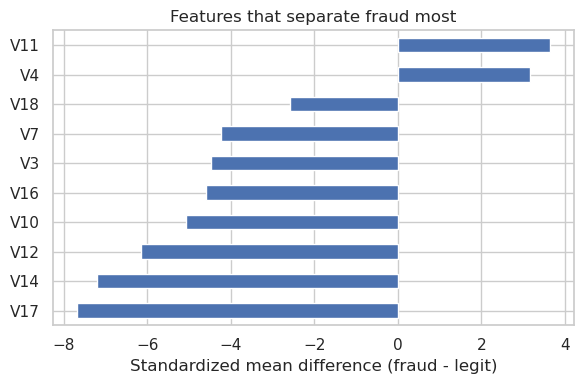

In [5]:
vcols = [f"V{i}" for i in range(1, 29)]
smd = ((df.loc[df["Class"] == 1, vcols].mean() - df.loc[df["Class"] == 0, vcols].mean()) / df[vcols].std())
smd = smd.reindex(smd.abs().sort_values(ascending=False).index).head(10)

plt.figure(figsize=(6, 4))
smd.sort_values().plot.barh(color="#4C72B0")
plt.xlabel("Standardized mean difference (fraud - legit)"); plt.title("Features that separate fraud most")
plt.tight_layout(); plt.show()

**Findings (from the run documented in this notebook):**
- **Fraud amounts are usually small, with a long tail.** Median fraud is 9.82 vs. 22.00 for legitimate transactions, yet the fraud mean (123.87) is higher because a few frauds are very large (max 2,125.87). Amount alone cannot separate the classes.
- **The fraud rate is spiky, not stable.** It peaks in the small hours (hour 2 at 1.34%, hours 26 and 28 at 1.56% and 1.52% of transactions) and is near zero in several daytime hours, which is one reason a chronological split matters: a shuffled split would hide this drift.
- **A few anonymized components carry most of the signal.** The largest standardized mean differences are V17 (-7.86), V14 (-7.29), V12 (-6.28), V10 (-5.22) and V16 (-4.73) — fraud scores sit far below legitimate ones on these components; most other components barely move between classes.

## 4. Features and a time-based split

Rows are sorted by `Time`. The first 60% is **train**, the next 20% **validation** (used for model choice and the threshold), and the last 20% **test** (used once). This mimics deployment, where the model only ever scores transactions that happen *after* the ones it learned from.

`Time` itself is not used as a feature because it only measures seconds since the first transaction and would not generalize. `hour` is derived from it as a rough time-of-day signal (it is relative to the first transaction, not the true clock).

In [6]:
df = df.sort_values("Time").reset_index(drop=True)
df["hour"] = (df["Time"] // 3600) % 24
df["log_amount"] = np.log1p(df["Amount"])

FEATURES = vcols + ["log_amount", "hour"]
n = len(df); i_train, i_val = int(n * 0.6), int(n * 0.8)
train, val, test = df.iloc[:i_train], df.iloc[i_train:i_val], df.iloc[i_val:]

X_train, y_train = train[FEATURES], train["Class"]
X_val,   y_val   = val[FEATURES],   val["Class"]
X_test,  y_test  = test[FEATURES],  test["Class"]
amt_val, amt_test = val["Amount"].values, test["Amount"].values

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {len(part):>7,} rows | {int(part['Class'].sum()):>4} frauds ({part['Class'].mean():.3%}) "
          f"| hours {part['Time'].min()/3600:5.1f} - {part['Time'].max()/3600:5.1f}")

train: 170,235 rows |  342 frauds (0.201%) | hours   0.0 -  33.4
val  :  56,745 rows |   57 frauds (0.100%) | hours  33.4 -  40.3
test :  56,746 rows |   74 frauds (0.130%) | hours  40.3 -  48.0


## 5. Models

Three approaches, all compared on the validation set with **PR-AUC (average precision)**. ROC-AUC is shown too, but with this much imbalance it looks flattering even for weak models.

- **Logistic regression:** simple supervised baseline
- **Isolation Forest:** unsupervised anomaly detection, never sees the labels. Useful when fraud labels are scarce or late
- **Gradient boosting:** tuned with `TimeSeriesSplit` cross-validation (each fold trains on the past and validates on the future)

In [7]:
val_scores = {}

logreg = Pipeline([("sc", StandardScaler()),
                   ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))])
logreg.fit(X_train, y_train)
val_scores["Logistic regression"] = logreg.predict_proba(X_val)[:, 1]

iso = IsolationForest(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train)   # labels not used
val_scores["Isolation Forest (unsupervised)"] = -iso.score_samples(X_val)                  # higher = more anomalous

In [8]:
param_dist = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [3, 4, 6],
    "max_leaf_nodes": [15, 31],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 1.0, 10.0],
    "max_iter": [150, 300],
    "class_weight": [None, {0: 1, 1: 10}, {0: 1, 1: 50}],
}
tscv = TimeSeriesSplit(n_splits=4)
search = RandomizedSearchCV(
    HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE),
    param_dist, n_iter=12, scoring="average_precision", cv=tscv,
    random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)

hgb = search.best_estimator_            # refit on the full training slice
print("Best params:", search.best_params_)
print(f"Time-series CV PR-AUC: {search.best_score_:.3f}")
val_scores["Gradient boosting (tuned)"] = hgb.predict_proba(X_val)[:, 1]

Best params: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 300, 'max_depth': 6, 'learning_rate': 0.1, 'l2_regularization': 10.0, 'class_weight': {0: 1, 1: 10}}
Time-series CV PR-AUC: 0.810


In [9]:
results = pd.DataFrame([
    {"model": k, "PR-AUC": average_precision_score(y_val, s), "ROC-AUC": roc_auc_score(y_val, s)}
    for k, s in val_scores.items()
]).sort_values("PR-AUC", ascending=False).round(3)
print(f"No-skill PR-AUC (= fraud rate in validation): {y_val.mean():.4f}")
results

No-skill PR-AUC (= fraud rate in validation): 0.0010


,model,PR-AUC,ROC-AUC
2,Gradient boosting (tuned),0.783,0.982
0,Logistic regression,0.760,0.972
1,Isolation Forest (unsupervised),0.020,0.931


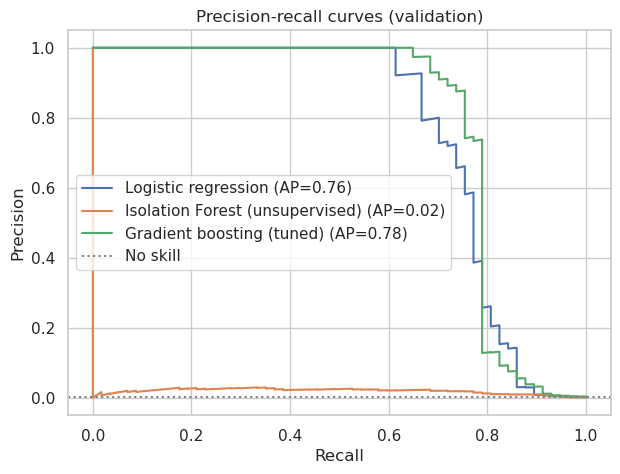

In [10]:
plt.figure(figsize=(7, 5))
for name, s in val_scores.items():
    p, r, _ = precision_recall_curve(y_val, s)
    plt.plot(r, p, label=f"{name} (AP={average_precision_score(y_val, s):.2f})")
plt.axhline(y_val.mean(), color="grey", ls=":", label="No skill")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-recall curves (validation)")
plt.legend(); plt.show()

**Model choice rule:** if tuned gradient boosting does not clearly beat logistic regression on validation PR-AUC, ship the simpler model. Compare the table above before continuing; the rest of the notebook uses the gradient boosting model (`hgb`), so switch that name if logistic regression wins.

## 6. Choosing how many alerts to raise

Every alert costs analyst time; every missed fraud costs money. We flag the transactions with the highest scores and choose the **alert rate** (share of transactions flagged) that maximizes net savings on the *validation* set:

`net savings = amount of fraud caught - review cost x number of alerts`

> **`REVIEW_COST` is an illustrative assumption.** Replace it with the real cost of one manual review. The model also assumes a flagged fraud is fully prevented, which is optimistic.

Thresholds are searched on the score *quantile* (alert rate) because fraud probabilities are extremely skewed, so a fixed grid like 0.1 to 0.9 would be too coarse.

Best alert rate: 0.089%  ->  threshold 0.6338
Net savings (validation): 7,501
Flag everything: -271,494  |  Flag nothing: 0


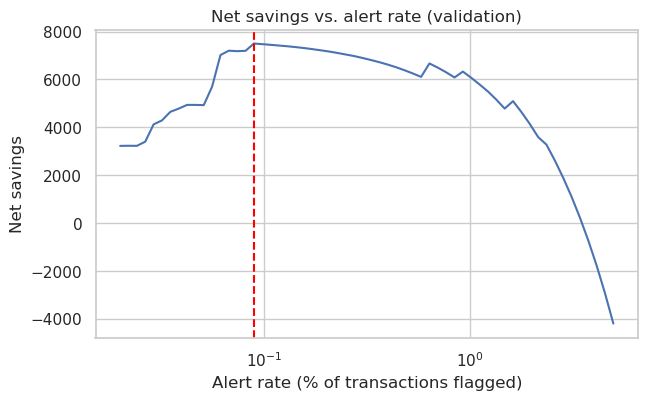

In [11]:
REVIEW_COST = 5.0   # cost of one manual review, in the same currency units as Amount

def net_savings(y_true, score, amount, threshold):
    flagged = score >= threshold
    caught = amount[flagged & (np.asarray(y_true) == 1)].sum()
    return float(caught - REVIEW_COST * flagged.sum())

s_val = val_scores["Gradient boosting (tuned)"]
alert_rates = np.logspace(np.log10(0.0002), np.log10(0.05), 60)
thresholds = np.quantile(s_val, 1 - alert_rates)
savings = np.array([net_savings(y_val, s_val, amt_val, t) for t in thresholds])

best = int(savings.argmax())
THRESHOLD = float(thresholds[best])
print(f"Best alert rate: {alert_rates[best]:.3%}  ->  threshold {THRESHOLD:.4f}")
print(f"Net savings (validation): {savings[best]:,.0f}")
print(f"Flag everything: {net_savings(y_val, s_val, amt_val, -np.inf):,.0f}  |  Flag nothing: 0")
if savings[best] <= 0:
    print("WARNING: no alert rate beats doing nothing under these cost assumptions")

plt.figure(figsize=(7, 4))
plt.plot(alert_rates * 100, savings); plt.axvline(alert_rates[best] * 100, color="red", ls="--")
plt.xscale("log"); plt.xlabel("Alert rate (% of transactions flagged)"); plt.ylabel("Net savings")
plt.title("Net savings vs. alert rate (validation)"); plt.show()

A flat curve near the optimum means the decision is robust to small errors in the cost assumption. Try halving and doubling `REVIEW_COST` and see how far the best alert rate moves.

## 7. Final evaluation on the test set (used once)

PR-AUC 0.785 | ROC-AUC 0.980  (no-skill PR-AUC 0.0013)
At threshold 0.6338: 65 alerts (0.115% of transactions)
Precision 0.846 | Recall 0.743
Fraud amount caught: 5,089 of 7,728 (65.8%)
Net savings (test): 4,764


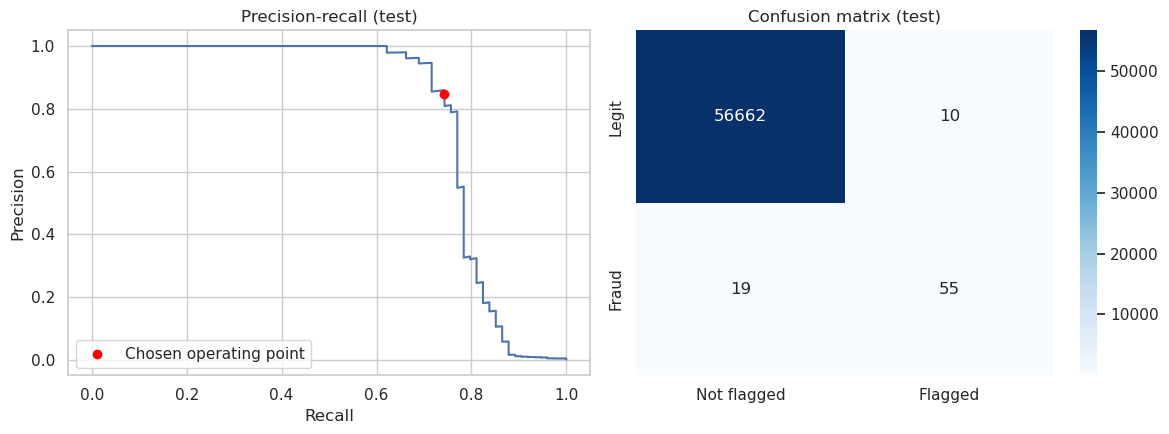

In [12]:
test_score = hgb.predict_proba(X_test)[:, 1]
flagged = test_score >= THRESHOLD
yt = y_test.values

prec = precision_score(yt, flagged, zero_division=0)
rec = recall_score(yt, flagged, zero_division=0)
total_fraud_amt = amt_test[yt == 1].sum()
caught_amt = amt_test[flagged & (yt == 1)].sum()

print(f"PR-AUC {average_precision_score(yt, test_score):.3f} | ROC-AUC {roc_auc_score(yt, test_score):.3f}"
      f"  (no-skill PR-AUC {yt.mean():.4f})")
print(f"At threshold {THRESHOLD:.4f}: {flagged.sum()} alerts ({flagged.mean():.3%} of transactions)")
print(f"Precision {prec:.3f} | Recall {rec:.3f}")
print(f"Fraud amount caught: {caught_amt:,.0f} of {total_fraud_amt:,.0f} ({caught_amt / total_fraud_amt:.1%})")
print(f"Net savings (test): {net_savings(yt, test_score, amt_test, THRESHOLD):,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
p, r, _ = precision_recall_curve(yt, test_score)
axes[0].plot(r, p); axes[0].scatter([rec], [prec], color="red", zorder=5, label="Chosen operating point")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision-recall (test)"); axes[0].legend()
sns.heatmap(confusion_matrix(yt, flagged), annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["Not flagged", "Flagged"], yticklabels=["Legit", "Fraud"])
axes[1].set_title("Confusion matrix (test)"); plt.tight_layout()
fig.savefig("../images/evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# The test set has few frauds, so quantify how uncertain the PR-AUC is (bootstrap, 200 resamples)
rng = np.random.default_rng(RANDOM_STATE)
idx = np.arange(len(yt))
aps = []
for _ in range(200):
    b = rng.choice(idx, size=len(idx), replace=True)
    if yt[b].sum() > 0:
        aps.append(average_precision_score(yt[b], test_score[b]))
lo, hi = np.percentile(aps, [2.5, 97.5])
print(f"Test PR-AUC 95% bootstrap interval: [{lo:.3f}, {hi:.3f}]  (frauds in test: {int(yt.sum())})")

Test PR-AUC 95% bootstrap interval: [0.693, 0.892]  (frauds in test: 74)


In [14]:
# Same test set, all three models (selection was done on validation, so this is just for reference)
test_all = {
    "Logistic regression": logreg.predict_proba(X_test)[:, 1],
    "Isolation Forest (unsupervised)": -iso.score_samples(X_test),
    "Gradient boosting (tuned)": test_score,
}
pd.DataFrame([{"model": k, "test PR-AUC": average_precision_score(yt, s)} for k, s in test_all.items()]).round(3)

,model,test PR-AUC
0,Logistic regression,0.746
1,Isolation Forest (unsupervised),0.036
2,Gradient boosting (tuned),0.785


In [15]:
# Alert-budget view: if analysts can only review a fixed share of transactions
rows = []
order = np.argsort(-test_score)
for rate in [0.0005, 0.001, 0.005, 0.01]:
    k = max(1, int(len(yt) * rate)); top = order[:k]
    rows.append({"alert budget": f"{rate:.2%}", "alerts": k,
                 "precision": round(yt[top].mean(), 3), "recall": round(yt[top].sum() / yt.sum(), 3)})
pd.DataFrame(rows)

,alert budget,alerts,precision,recall
0,0.05%,28,1.000,0.378
1,0.10%,56,0.946,0.716
2,0.50%,283,0.216,0.824
3,1.00%,567,0.111,0.851


## 8. Understanding the model

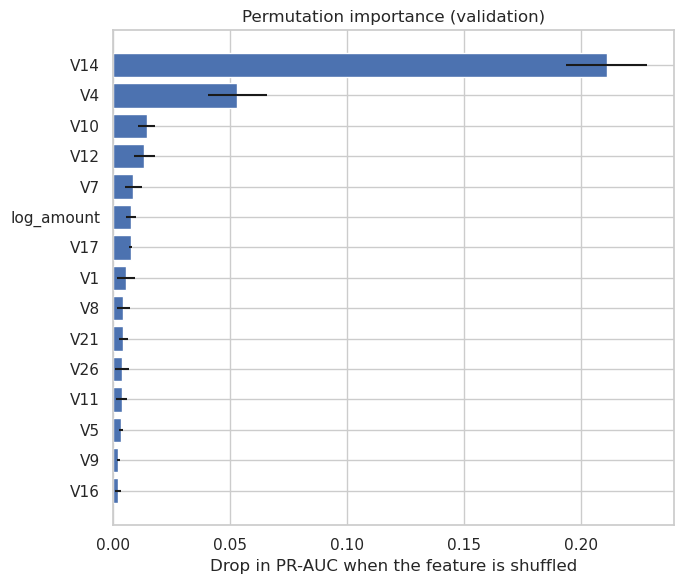

In [16]:
perm = permutation_importance(hgb, X_val, y_val, scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values().tail(15)
imp_std = pd.Series(perm.importances_std, index=FEATURES)[imp.index]

plt.figure(figsize=(7, 6))
plt.barh(imp.index, imp.values, xerr=imp_std.values, color="#4C72B0")
plt.xlabel("Drop in PR-AUC when the feature is shuffled"); plt.title("Permutation importance (validation)")
plt.tight_layout(); plt.show()

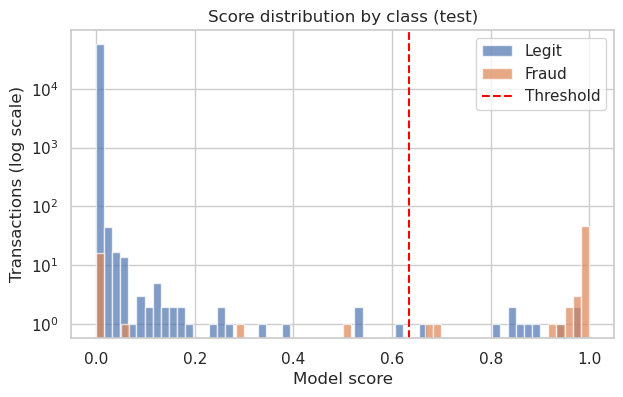

In [17]:
plt.figure(figsize=(7, 4))
plt.hist(test_score[yt == 0], bins=60, alpha=0.7, label="Legit", log=True)
plt.hist(test_score[yt == 1], bins=60, alpha=0.7, label="Fraud", log=True)
plt.axvline(THRESHOLD, color="red", ls="--", label="Threshold")
plt.xlabel("Model score"); plt.ylabel("Transactions (log scale)"); plt.title("Score distribution by class (test)")
plt.legend(); plt.show()

Because `V1`-`V28` are anonymized PCA components, feature importance here shows *that* certain components matter but not *what they mean in business terms*. With a real payment dataset, importance on named features (merchant category, device, country, velocity) would be much more actionable.

## 9. Save the model

In [18]:
Path("../models").mkdir(exist_ok=True)
joblib.dump(hgb, "../models/fraud_model.joblib")
with open("../models/threshold.json", "w") as f:
    json.dump({"threshold": THRESHOLD, "review_cost": REVIEW_COST}, f)
print("Saved model and threshold")

Saved model and threshold


## 10. Limitations and next steps

- **Two days of data** from European cardholders (2013), so seasonality and long-term drift cannot be tested, and the patterns are not Indonesian payment behavior.
- **Few frauds in the test slice**, so metrics are noisy; the bootstrap interval above shows how much.
- **Anonymized PCA features** limit interpretability and mean no feature engineering on merchant, device, or customer history.
- **Label delay:** in production, fraud labels arrive days or weeks later (chargebacks), so a model is always trained on older data than it scores.
- **Adversarial drift:** fraudsters adapt, so the model needs monitoring and regular retraining.
- **Cost assumptions** (`REVIEW_COST`, full prevention of flagged fraud, no customer-friction cost for false alarms) are simplifications.
- Next steps: IEEE-CIS dataset with richer features (device, email domain, transaction history), velocity features, SHAP, probability calibration, and a drift-monitoring plan.